In [1]:
# Chit 2: Sign Language FNN: accuracy and loss graphs
# Step 1: Import the libraries
import numpy as np
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense
import pandas as pd
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt

In [2]:
# Step 2: Load and prepare Sign Language MNIST
train_df = pd.read_csv("sign_mnist_train.csv")
test_df = pd.read_csv("sign_mnist_test.csv")

X_train = train_df.drop(columns="label").to_numpy(dtype="float32") / 255.0
X_test = test_df.drop(columns="label").to_numpy(dtype="float32") / 255.0

encoder = LabelEncoder()
y_train = encoder.fit_transform(train_df["label"])
y_test = encoder.transform(test_df["label"])
class_names = [chr(int(label) + 65) for label in encoder.classes_]
image_shape = (28, 28, 1)

In [3]:
# Step 3: Flatten the images
X_train = X_train.reshape(-1, 28, 28).reshape(-1, 784)
X_test = X_test.reshape(-1, 28, 28).reshape(-1, 784)

In [4]:
# Step 4: Build the model
num_classes = len(class_names)
model = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(256, activation="relu"),
    Dense(128, activation="relu"),
    Dense(num_classes, activation="softmax")
])

In [5]:
# Step 5: Compile and train
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [6]:
# Step 6: Prepare and run the model
history = model.fit(
    X_train, y_train,
    epochs=15,
    batch_size=128,
    validation_split=0.1,
    verbose=0
)

In [7]:
# Step 7: Evaluate on test data
_, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
train_accuracy = history.history["accuracy"][-1]
print(f"Training accuracy: {train_accuracy * 100:.2f}%")
print(f"Testing accuracy:  {test_accuracy * 100:.2f}%")

Training accuracy: 99.47%
Testing accuracy:  75.96%


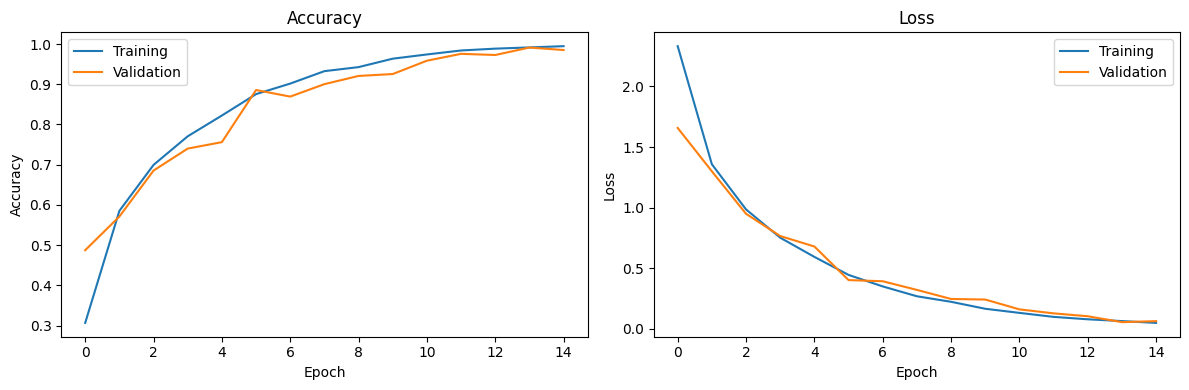

In [8]:
# Step 8: Plot accuracy and loss
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.tight_layout()
plt.show()